In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/heritier1/telco-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
dataf = pd.read_csv("/kaggle/input/datasets/heritier1/telco-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
dataf.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
dataf.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
dataf["Churn"] = dataf["Churn"].map({"Yes": 1, "No": 0})

In [6]:
dataf

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,0
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,0
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,1


**Changed the churn attribute to contain 1 and 0 instead of Yes and No**

In [7]:
print(dataf.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object


**Datatypes not changed**

In [8]:
print(dataf.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


**There is no attribute with null values or missing values**

In [9]:
print(dataf.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def analyze_churn(dataf, feature, target="Churn"):
    # Work with only the columns needed for this analysis
    data = dataf[[feature, target]].copy()

    # Remove rows missing either value for this particular analysis
    data = data.dropna(subset=[feature, target])

    # Normalize common whitespace issues in text categories
    for col in [feature, target]:
        if data[col].dtype == "object":
            data[col] = data[col].str.strip()

    # Calculate counts and churn rates
    summary = (
        data.groupby(feature, observed=True)[target]
        .agg(
            Customers="size",
            Churned=lambda s: s.eq(1).sum()
        )
    )

    summary["Not_Churned"] = (
        summary["Customers"] - summary["Churned"]
    )

    summary["Churn_Rate_%"] = (
        summary["Churned"] / summary["Customers"] * 100
    )

    summary = summary.sort_values(
        "Churn_Rate_%", ascending=False
    )

    print(f"\nAnalysis: {feature} vs {target}")
    print(summary.round(2))

    # Visualize churn rate by category
    ax = summary["Churn_Rate_%"].plot(
        kind="bar",
        figsize=(8, 5),
        rot=30
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Customers Who Churned (%)")
    ax.set_ylim(0, 100)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

   # plt.tight_layout()
    plt.show()

    return summary


**The above is a churn analysis function that will be used to analyse churn against other attributes**

In [11]:
print("Missing churn values:", dataf["Churn"].isna().sum())

Missing churn values: 0


In [12]:
import glob

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print(files)

['/kaggle/input/datasets/heritier1/telco-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [13]:
import pandas as pd

dataf = pd.read_csv("/kaggle/input/datasets/heritier1/telco-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(dataf["Churn"].value_counts(dropna=False))

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [14]:
dataf["Churn"] = dataf["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(dataf["Churn"].value_counts(dropna=False))

Churn
0    5174
1    1869
Name: count, dtype: int64



Analysis: gender vs Churn
        Customers  Churned  Not_Churned  Churn_Rate_%
gender                                               
Female       3488      939         2549         26.92
Male         3555      930         2625         26.16


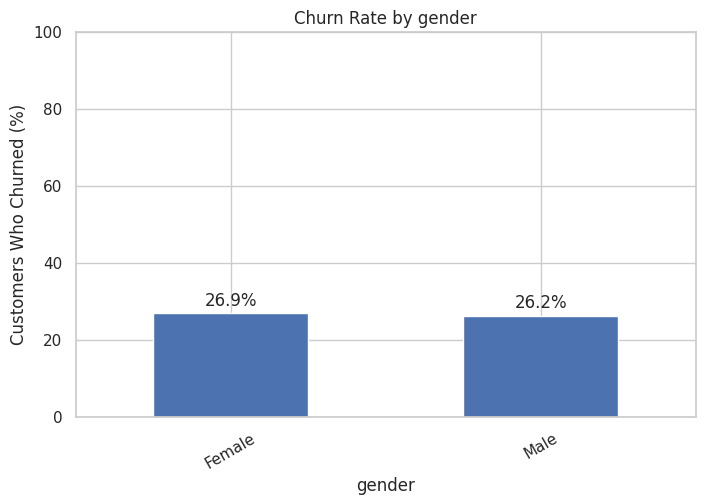


Analysis: SeniorCitizen vs Churn
               Customers  Churned  Not_Churned  Churn_Rate_%
SeniorCitizen                                               
1                   1142      476          666         41.68
0                   5901     1393         4508         23.61


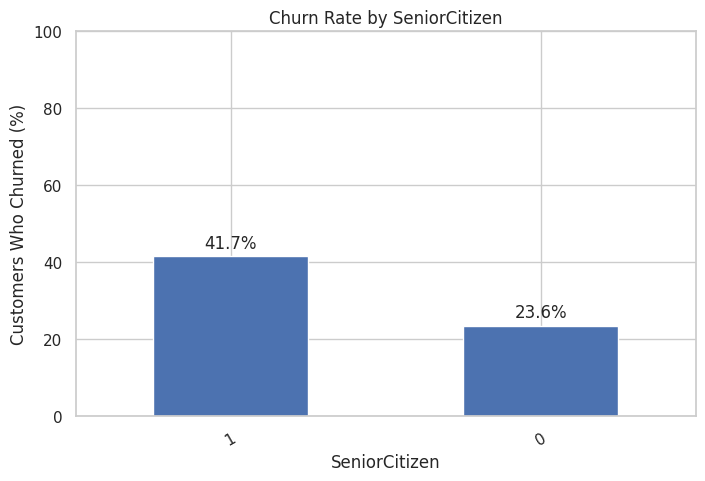


Analysis: Partner vs Churn
         Customers  Churned  Not_Churned  Churn_Rate_%
Partner                                               
No            3641     1200         2441         32.96
Yes           3402      669         2733         19.66


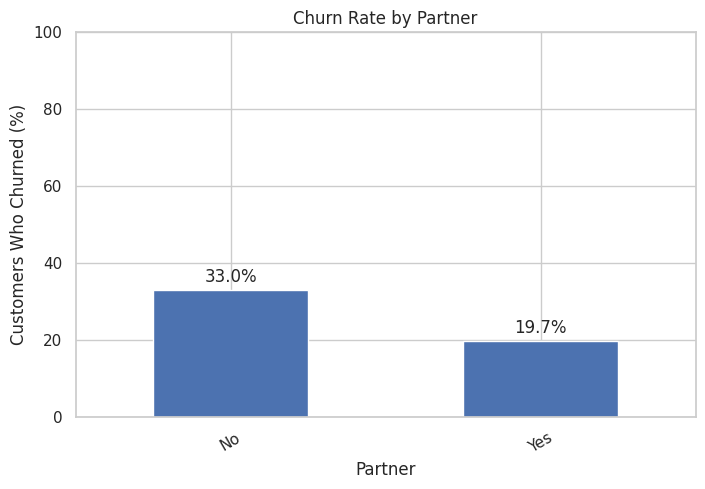


Analysis: Dependents vs Churn
            Customers  Churned  Not_Churned  Churn_Rate_%
Dependents                                               
No               4933     1543         3390         31.28
Yes              2110      326         1784         15.45


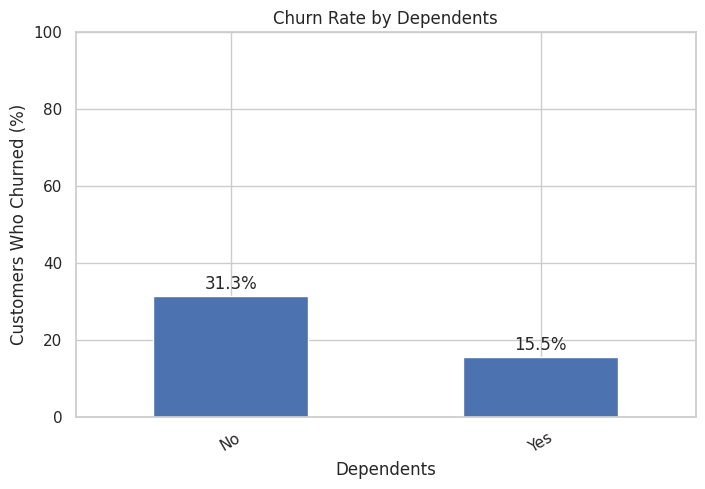


Analysis: PhoneService vs Churn
              Customers  Churned  Not_Churned  Churn_Rate_%
PhoneService                                               
Yes                6361     1699         4662         26.71
No                  682      170          512         24.93


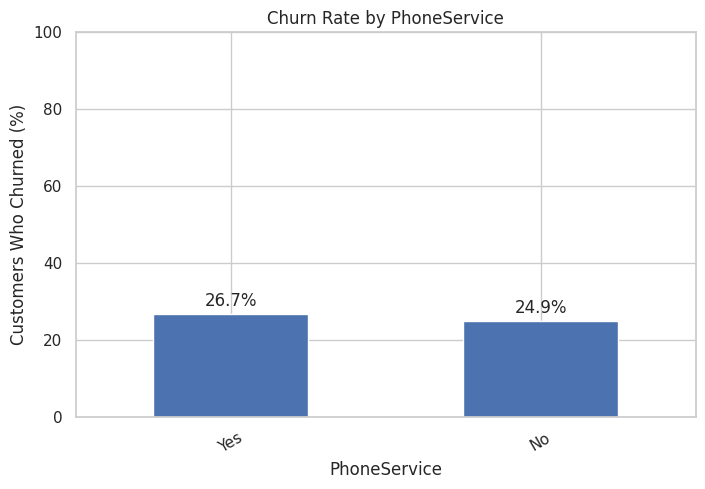


Analysis: Contract vs Churn
                Customers  Churned  Not_Churned  Churn_Rate_%
Contract                                                     
Month-to-month       3875     1655         2220         42.71
One year             1473      166         1307         11.27
Two year             1695       48         1647          2.83


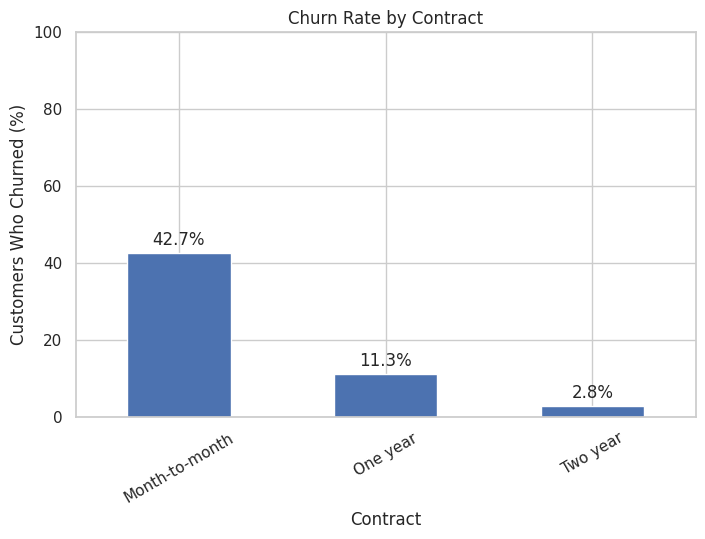


Analysis: PaperlessBilling vs Churn
                  Customers  Churned  Not_Churned  Churn_Rate_%
PaperlessBilling                                               
Yes                    4171     1400         2771         33.57
No                     2872      469         2403         16.33


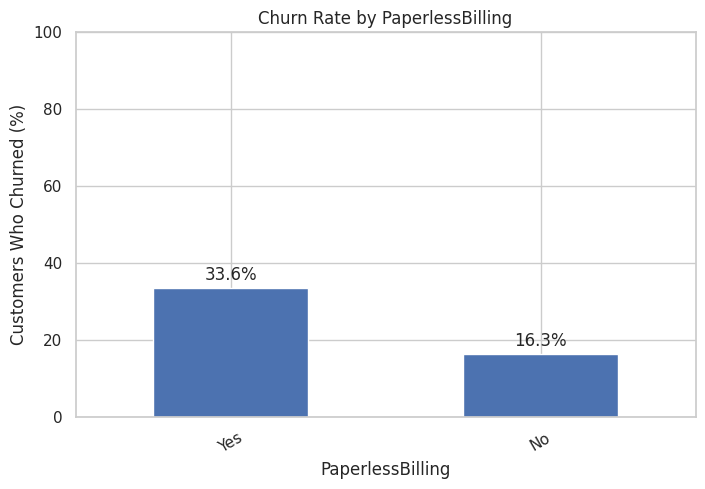


Analysis: PaymentMethod vs Churn
                           Customers  Churned  Not_Churned  Churn_Rate_%
PaymentMethod                                                           
Electronic check                2365     1071         1294         45.29
Mailed check                    1612      308         1304         19.11
Bank transfer (automatic)       1544      258         1286         16.71
Credit card (automatic)         1522      232         1290         15.24


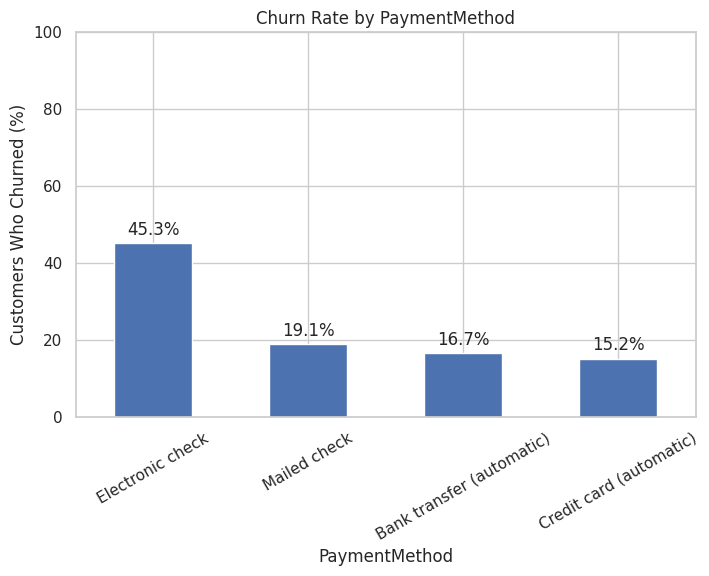

In [15]:

# Demographic analysis
demographic_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

# Service analysis
service_features = [
    "PhoneService"
]

# Payments and contract analysis
payment_features = [
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

for feature in demographic_features:
    analyze_churn(dataf, feature)

for feature in service_features:
    analyze_churn(dataf, feature)

for feature in payment_features:
    analyze_churn(dataf, feature)


# What I learnt from output of each cell

Overall churn rate is about **26.5%** (1,869 of 7,043 customers). Every feature below is compared against this baseline.

| Feature | Churn rates | Gap | Signal |
|---|---|---|---|
| **Contract** | Month-to-month 42.7%, One year 11.3%, Two year 2.8% | ~15x | Very strong |
| **PaymentMethod** | Electronic check 45.3%, others 15-19% | ~3x | Strong |
| **PaperlessBilling** | Yes 33.6%, No 16.3% | ~2x | Strong |
| **SeniorCitizen** | Senior 41.7%, Non-senior 23.6% | ~1.8x | Moderate to strong |
| **Dependents** | No 31.3%, Yes 15.5% | ~2x | Moderate to strong |
| **Partner** | No 33.0%, Yes 19.7% | ~1.7x | Moderate |
| **PhoneService** | Yes 26.7%, No 24.9% | ~1.8 pts | Negligible |
| **gender** | Female 26.9%, Male 26.2% | ~0.8 pts | None |

**What each output tells us**
- **Contract:** the strongest driver. Month-to-month customers are 55% of the base but about 89% of churners. Two-year customers are locked in and rarely leave.
- **PaymentMethod:** electronic check is about 34% of customers but about 57% of churners. Automatic methods (bank transfer, credit card) have the lowest churn.
- **PaperlessBilling:** twice the churn rate, about 75% of churners. Likely a proxy for electronic check and month-to-month contracts rather than a direct effect.
- **SeniorCitizen:** only 16% of customers but 41.7% churn, so this is a high-risk segment.
- **Dependents and Partner:** customers with a household tie churn about half as much. The two are probably correlated.
- **PhoneService and gender:** no meaningful relationship. Two-proportion z-tests show no significant difference (z of roughly 1.0 and 0.7).

